<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_13_Deploying_scikit_learn_Models_in_Production.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 13 — Deploying scikit-learn Models in Production (Menerapkan Model scikit-learn ke Produksi)

**Referensi:** *scikit-learn Cookbook, Third Edition* — Bab 13, “Deploying scikit-learn Models in Production”.

Notebook ini mengikuti enam pokok bahasan bab, tetapi memakai alur dan contoh yang disusun secara mandiri: mengemas pipeline prapemrosesan dan model, memvalidasi artefak tersimpan, membandingkan pola inferensi, menyimulasikan pemantauan, mencatat metadata model, dan membuat gerbang kualitas sebelum deployment.

> **Tujuan:** memperlakukan model yang sudah dilatih sebagai artefak perangkat lunak yang perlu dipelihara—bukan sekadar model yang berjalan di dalam notebook.

## Tujuan pembelajaran

Setelah menyelesaikan notebook ini, kamu diharapkan mampu:

1. Menjelaskan tahapan utama dari pengembangan model sampai layanan produksi.
2. Menyimpan dan memulihkan pipeline scikit-learn sambil memeriksa konsistensi prediksi.
3. Membandingkan inferensi satu baris dengan inferensi batch dan menjelaskan pilihan scaling sederhana.
4. Memantau kualitas model dan perubahan distribusi masukan ketika label atau data acuan tersedia.
5. Melacak versi serta metadata model sepanjang siklus hidupnya.
6. Membuat gerbang validasi otomatis sederhana sebelum model disetujui untuk deployment.

**Lingkungan:** Python 3.9+ dan scikit-learn. Contoh menggunakan dataset bawaan sehingga tidak membutuhkan unduhan dataset eksternal.

## 13.1 — Dari eksperimen menuju layanan produksi

Deployment model memindahkan alur kerja yang sudah dilatih ke lingkungan tempat aplikasi atau pengguna dapat meminta prediksi. Alur deployment sederhana adalah:

**siapkan data → latih dan evaluasi → kemas prapemrosesan + model → simpan artefak dan metadata → validasi artefak → layani prediksi → pantau → perbarui atau latih ulang**

Persyaratan deployment lebih luas daripada akurasi prediksi. Persyaratan dapat mencakup latensi respons, throughput, penggunaan sumber daya, kecocokan versi pustaka, reproduksibilitas, keamanan, dan prosedur pemulihan ke versi sebelumnya (*rollback*).

In [ ]:
import json
import os
import pickle
import platform
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
ARTIFACT_DIR = Path("chapter13_artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

print(f"Python: {platform.python_version()}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"Direktori artefak: {ARTIFACT_DIR.resolve()}")

Python: 3.13.5
scikit-learn: 1.8.0
Direktori artefak: /mnt/data/chapter13_artifacts


### Menetapkan baseline yang dapat direproduksi

Kita menggunakan dataset kanker payudara bawaan scikit-learn sebagai contoh klasifikasi biner. `Pipeline` menggabungkan scaling dan klasifikasi sehingga langkah prapemrosesan yang sama digunakan saat pelatihan maupun prediksi berikutnya. Data uji disisihkan untuk evaluasi dan tidak digunakan untuk mempelajari model.

In [ ]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

model_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
model_pipeline.fit(X_train, y_train)

train_predictions = model_pipeline.predict(X_train)
test_predictions = model_pipeline.predict(X_test)

print(f"Baris data latih: {len(X_train)} | Baris data hold-out: {len(X_test)}")
print(f"Akurasi data latih: {accuracy_score(y_train, train_predictions):.3f}")
print(f"Akurasi data hold-out:  {accuracy_score(y_test, test_predictions):.3f}")

Baris data latih: 426 | Baris data hold-out: 143
Akurasi data latih: 0.988
Akurasi data hold-out:  0.986


In [ ]:
report = pd.DataFrame(
    classification_report(
        y_test, test_predictions,
        target_names=dataset.target_names,
        output_dict=True,
        zero_division=0
    )
).T
report.round(3)

,precision,recall,f1-score,support
malignant,0.981,0.981,0.981,53.000
benign,0.989,0.989,0.989,90.000
accuracy,0.986,0.986,0.986,0.986
macro avg,0.985,0.985,0.985,143.000
weighted avg,0.986,0.986,0.986,143.000


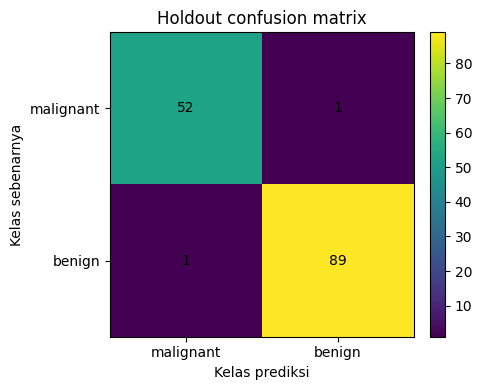

In [ ]:
cm = confusion_matrix(y_test, test_predictions)
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, interpolation="nearest")
ax.set_title("Holdout confusion matrix")
ax.set_xlabel("Kelas prediksi")
ax.set_ylabel("Kelas sebenarnya")
ax.set_xticks([0, 1], labels=dataset.target_names)
ax.set_yticks([0, 1], labels=dataset.target_names)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

**Interpretasi:** metrik dari data uji yang disisihkan memberikan perkiraan awal kinerja masa depan yang lebih realistis dibandingkan akurasi data latih saja. Metrik yang paling berguna bergantung pada konsekuensi *false positive* dan *false negative* dalam aplikasi yang dituju.

## 13.2 — Serialisasi dan persistensi

Serialisasi menyimpan objek yang telah dilatih ke file agar bisa dimuat kembali tanpa melatih ulang. Jika diperlukan prapemrosesan, artefak sebaiknya menyimpan seluruh alur inferensi.

Pilihan yang umum di Python:

- **`joblib`** — praktis untuk objek scikit-learn yang memuat array NumPy.
- **`pickle`** — mekanisme serialisasi objek umum di Python.
- **Format interoperabilitas** seperti ONNX dapat berguna jika model akan dijalankan di luar lingkungan Python, tetapi dukungan konversi bergantung pada estimator dan operator yang digunakan.

**Keamanan dan kompatibilitas:** hanya muat file serialisasi dari sumber tepercaya. Memuat file pickle/joblib dapat menjalankan kode. Catat versi Python dan paket yang digunakan; kompatibilitas antarversi scikit-learn tidak dijamin.

In [ ]:
model_path = ARTIFACT_DIR / "breast_cancer_pipeline_v1.joblib"
joblib.dump(model_pipeline, model_path)

restored_pipeline = joblib.load(model_path)
restored_predictions = restored_pipeline.predict(X_test)

same_predictions = np.array_equal(test_predictions, restored_predictions)
print(f"Disimpan ke: {model_path}")
print(f"Ukuran artefak: {model_path.stat().st_size:,} bytes")
print(f"Prediksi sama sebelum dan sesudah dimuat ulang: {same_predictions}")
assert same_predictions, "Reloaded artifact changed predictions."

Disimpan ke: chapter13_artifacts/breast_cancer_pipeline_v1.joblib
Ukuran artefak: 3,089 bytes
Prediksi sama sebelum dan sesudah dimuat ulang: True


In [ ]:
# Perbandingan opsional: serialisasikan objek terlatih yang sama menggunakan pickle.
pickle_path = ARTIFACT_DIR / "breast_cancer_pipeline_v1.pkl"
with pickle_path.open("wb") as file:
    pickle.dump(model_pipeline, file)

with pickle_path.open("rb") as file:
    pickle_pipeline = pickle.load(file)

print(f"Berkas joblib: {model_path.stat().st_size:,} bytes")
print(f"Berkas pickle: {pickle_path.stat().st_size:,} bytes")
print("Prediksi model pickle setelah dimuat ulang sama:", np.array_equal(
    model_pipeline.predict(X_test), pickle_pipeline.predict(X_test)
))

Berkas joblib: 3,089 bytes
Berkas pickle: 2,671 bytes
Prediksi model pickle setelah dimuat ulang sama: True


Ukuran file hanya salah satu aspek perbandingan dan tidak membuktikan bahwa satu format selalu lebih baik. Pemeriksaan utama pada bagian ini adalah memastikan artefak yang dipulihkan menerima skema masukan yang diharapkan dan menghasilkan kembali prediksi yang sama dengan model asli.

## 13.3 — Menskalakan inferensi untuk produksi

Istilah **scaling** dapat mengacu pada beberapa hal: menangani lebih banyak permintaan, memperpendek waktu respons, menggunakan sumber daya CPU yang tersedia, atau memproses data secara batch. Untuk model scikit-learn, mengelompokkan permintaan dalam batch dapat mengurangi overhead pemanggilan Python. Beberapa estimator dan alur pencarian juga mendukung pekerjaan paralel melalui parameter seperti `n_jobs`.

Benchmark berikut hanya berupa demonstrasi waktu eksekusi lokal. Hasil bergantung pada perangkat keras, beban kerja, dan kondisi sistem, sehingga tidak boleh dianggap sebagai jaminan kapasitas produksi.

In [ ]:
# Bandingkan pemanggilan satu baris berulang dengan satu pemanggilan batch pada catatan yang sama.
benchmark_X = X_test.iloc[:min(100, len(X_test))]

start = time.perf_counter()
single_predictions = np.array([
    restored_pipeline.predict(benchmark_X.iloc[[i]])[0]
    for i in range(len(benchmark_X))
])
single_elapsed = time.perf_counter() - start

start = time.perf_counter()
batch_predictions = restored_pipeline.predict(benchmark_X)
batch_elapsed = time.perf_counter() - start

print(f"Jumlah baris yang dievaluasi: {len(benchmark_X)}")
print(f"Total waktu satu per satu: {single_elapsed:.6f} seconds")
print(f"Total waktu batch:      {batch_elapsed:.6f} seconds")
print("Prediksi konsisten:", np.array_equal(single_predictions, batch_predictions))

Jumlah baris yang dievaluasi: 100
Total waktu satu per satu: 0.069680 seconds
Total waktu batch:      0.001125 seconds
Prediksi konsisten: True


In [ ]:
# Simpan prapemrosesan di dalam pipeline agar setiap fold CV melatih scaler-nya sendiri.
# Ini mencegah statistik fitur dari fold validasi bocor ke proses pelatihan fold tersebut.
cv_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
cv_scores = cross_val_score(
    cv_pipeline, X_train, y_train,
    cv=5, scoring="accuracy", n_jobs=1
)

print("Skor akurasi 5-fold:", np.round(cv_scores, 3))
print(f"Rata-rata akurasi CV: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

Skor akurasi 5-fold: [0.977 0.976 0.953 0.965 0.976]
Rata-rata akurasi CV: 0.969 ± 0.009


Pada layanan nyata, benchmark perlu mencakup ukuran masukan yang mewakili penggunaan sebenarnya, permintaan serentak, *cold start*, penggunaan memori, timeout, dan penanganan error. Pemrosesan batch cocok ketika persyaratan latensi memungkinkan permintaan digabungkan; permintaan interaktif yang harus dijawab langsung mungkin memerlukan rancangan layanan berbeda.

## 13.4 — Memantau dan memperbarui model yang sudah di-deploy

Deployment bukan akhir dari evaluasi model. Seiring waktu, data masukan dapat berubah (**data drift**) atau hubungan antara fitur dan hasil dapat berubah (**concept drift**). Pemantauan dapat mencakup:

- pemeriksaan skema masukan dan kualitas data;
- ringkasan distribusi fitur masuk dibandingkan baseline;
- latensi, error, volume permintaan, dan penggunaan sumber daya;
- metrik kualitas ketika label acuan tersedia;
- ambang peringatan yang jelas serta prosedur tinjauan, pelatihan ulang, dan rollback.

Sel berikutnya menyimulasikan pergeseran untuk tujuan belajar. Batch yang bergeser diubah secara artifisial dan tidak dimaksudkan sebagai contoh drift dunia nyata yang telah tervalidasi.

In [ ]:
# Baseline distribusi fitur dipelajari hanya dari data latih.
train_mean = X_train.mean()
train_std = X_train.std().replace(0, 1)

# Gunakan data hold-out sebagai aliran masukan simulasi kecil.
monitor_X = X_test.reset_index(drop=True).copy()
monitor_y = y_test.reset_index(drop=True).copy()

# Ubah batch terakhir secara artifisial untuk menunjukkan cara mendeteksi pergeseran masukan.
num_batches = min(4, len(monitor_X))
batch_indices = np.array_split(np.arange(len(monitor_X)), num_batches)
stream_batches = []
for batch_number, indices in enumerate(batch_indices, start=1):
    batch_X = monitor_X.iloc[indices].copy()
    batch_y = monitor_y.iloc[indices].copy()
    if batch_number == num_batches:
        # Tambahkan 1,25 simpangan baku data latih pada beberapa fitur terpilih.
        changed_features = list(X.columns[:3])
        for feature in changed_features:
            batch_X.loc[:, feature] = batch_X[feature] + 1.25 * train_std[feature]
    stream_batches.append((batch_X, batch_y))

print(f"Jumlah batch masukan simulasi: {len(stream_batches)}")
print("Hanya batch terakhir yang sengaja diubah untuk demonstrasi.")

Jumlah batch masukan simulasi: 4
Hanya batch terakhir yang sengaja diubah untuk demonstrasi.


In [ ]:
batch_records = []
for batch_number, (batch_X, batch_y) in enumerate(stream_batches, start=1):
    batch_predictions = restored_pipeline.predict(batch_X)
    standardized_mean_shift = ((batch_X.mean() - train_mean) / train_std).abs()
    batch_records.append({
        "batch": batch_number,
        "rows": len(batch_X),
        "accuracy": accuracy_score(batch_y, batch_predictions),
        "largest_mean_shift_z": standardized_mean_shift.max(),
        "feature_with_largest_shift": standardized_mean_shift.idxmax(),
    })

monitoring_results = pd.DataFrame(batch_records)
monitoring_results.round(3)

,batch,rows,accuracy,largest_mean_shift_z,feature_with_largest_shift
0,1,36,1.000,0.277,worst fractal dimension
1,2,36,1.000,0.309,worst symmetry
2,3,36,1.000,0.336,area error
3,4,35,0.857,1.297,mean texture


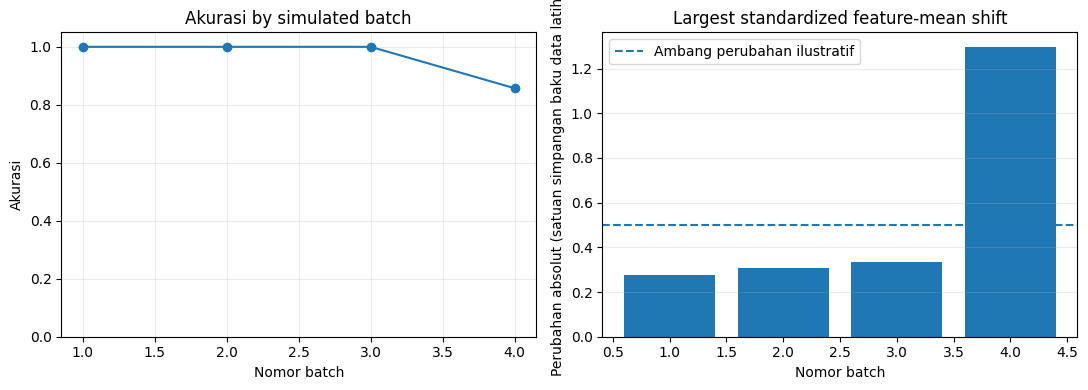

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(monitoring_results["batch"], monitoring_results["accuracy"], marker="o")
axes[0].set_title("Akurasi by simulated batch")
axes[0].set_xlabel("Nomor batch")
axes[0].set_ylabel("Akurasi")
axes[0].set_ylim(0, 1.05)
axes[0].grid(alpha=0.25)

axes[1].bar(monitoring_results["batch"], monitoring_results["largest_mean_shift_z"])
axes[1].axhline(0.5, linestyle="--", label="Ambang perubahan ilustratif")
axes[1].set_title("Largest standardized feature-mean shift")
axes[1].set_xlabel("Nomor batch")
axes[1].set_ylabel("Perubahan absolut (satuan simpangan baku data latih)")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
# Aturan ilustratif; ambang harus ditetapkan berdasarkan kebutuhan bisnis dan validasi.
accuracy_floor = 0.80
shift_threshold = 0.50
last_batch = monitoring_results.iloc[-1]

if last_batch["accuracy"] < accuracy_floor:
    print("PERINGATAN: kualitas terukur berada di bawah batas minimum yang ditetapkan.")
else:
    print("Pemeriksaan kualitas: akurasi berada di atas batas minimum yang ditetapkan.")

if last_batch["largest_mean_shift_z"] > shift_threshold:
    print("PERINGATAN: rata-rata fitur masukan berbeda dari baseline data latih.")
else:
    print("Pemeriksaan pergeseran masukan: ringkasan statistik ini tidak melewati ambang.")

Pemeriksaan kualitas: akurasi berada di atas batas minimum yang ditetapkan.
PERINGATAN: rata-rata fitur masukan berbeda dari baseline data latih.


**Penting:** akurasi belum dapat dihitung sebelum label tersedia. Pergeseran distribusi fitur merupakan sinyal peringatan awal, bukan bukti bahwa prediksi sudah salah. Keputusan pemantauan sebaiknya menggabungkan kualitas data, metrik model, konteks bidang, dan proses peninjauan peringatan—bukan langsung melatih ulang setiap kali suatu ambang terlewati.

## 13.5 — Mengelola siklus hidup model

Siklus hidup model biasanya mencakup pengembangan, validasi, persetujuan, rilis, pemantauan, dan akhirnya penggantian atau rollback. Catatan artefak yang baik perlu membantu menjawab:

- Model dan langkah prapemrosesan apa yang sedang berjalan?
- Data pelatihan dan versi perangkat lunak apa yang digunakan?
- Berapa skor validasinya dan ambang apa yang dipersyaratkan?
- Kapan artefak dibuat dan bagaimana kembali ke versi sebelumnya?

Contoh ini menyimpan file metadata JSON kecil di samping artefak model. Pada sistem yang lebih besar, catatan semacam ini dapat dikelola melalui *model registry* atau platform pelacakan eksperimen.

In [ ]:
model_version = "1.1.0"
holdout_accuracy = float(accuracy_score(y_test, restored_pipeline.predict(X_test)))
metadata = {
    "model_name": "breast_cancer_logistic_pipeline",
    "model_version": model_version,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "estimator": "Pipeline(StandardScaler, LogisticRegression)",
    "dataset": "sklearn.datasets.load_breast_cancer",
    "n_training_rows": int(len(X_train)),
    "n_features": int(X_train.shape[1]),
    "feature_names": list(X_train.columns),
    "holdout_accuracy": holdout_accuracy,
    "python_version": platform.python_version(),
    "scikit_learn_version": sklearn.__version__,
    "artifact_file": model_path.name,
    "validation_split_seed": RANDOM_STATE,
}

metadata_path = ARTIFACT_DIR / f"model_metadata_v{model_version}.json"
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(f"Metadata disimpan ke: {metadata_path}")
print(metadata_path.read_text(encoding="utf-8")[:700] + "...")

Metadata disimpan ke: chapter13_artifacts/model_metadata_v1.1.0.json
{
  "model_name": "breast_cancer_logistic_pipeline",
  "model_version": "1.1.0",
  "created_at_utc": "2026-10-24T01:28:40.663836+00:00",
  "estimator": "Pipeline(StandardScaler, LogisticRegression)",
  "dataset": "sklearn.datasets.load_breast_cancer",
  "n_training_rows": 426,
  "n_features": 30,
  "feature_names": [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean compactness",
    "mean concavity",
    "mean concave points",
    "mean symmetry",
    "mean fractal dimension",
    "radius error",
    "texture error",
    "perimeter error",
    "area error",
    "smoothness error",
    "compactness error",
    "concavity error",
  ...


Nama file berversi dan metadata membantu mencegah artefak diganti tanpa jejak. Jangan menyimpan kredensial, data pribadi, atau rahasia di dalam metadata. Hubungkan artefak dan metadata melalui ID versi atau hash konten, serta simpan versi yang diketahui berfungsi baik untuk rollback.

## 13.6 — Membuat pipeline validasi deployment

Pipeline deployment sederhana dapat mengotomatiskan pemeriksaan berikut:

1. membangun pipeline prapemrosesan dan model;
2. melatihnya menggunakan data latih;
3. melakukan serialisasi pada seluruh pipeline;
4. memuat ulang artefak serialisasi sebagai pemeriksaan yang menyerupai lingkungan produksi;
5. mengevaluasi data uji yang tidak digunakan untuk pelatihan atau pemilihan hyperparameter;
6. menyetujui deployment hanya jika metrik memenuhi ambang yang ditentukan.

Ambang di bawah hanya ilustrasi. Dalam praktik, ambang harus mencerminkan risiko tugas dan kebutuhan operasional, bukan dipilih hanya agar demonstrasi berhasil.

In [ ]:
# Bangun artefak kandidat dari pembagian data latih dan ekspor dengan versi baru.
candidate_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
candidate_pipeline.fit(X_train, y_train)

candidate_path = ARTIFACT_DIR / "candidate_pipeline_v1_1.joblib"
joblib.dump(candidate_pipeline, candidate_path)
production_candidate = joblib.load(candidate_path)

candidate_preds = production_candidate.predict(X_test)
candidate_accuracy = accuracy_score(y_test, candidate_preds)
required_accuracy = 0.90

print(f"Artefak kandidat: {candidate_path.name}")
print(f"Akurasi data hold-out: {candidate_accuracy:.3f}")
print(f"Batas minimum yang diperlukan: {required_accuracy:.3f}")

Artefak kandidat: candidate_pipeline_v1_1.joblib
Akurasi data hold-out: 0.986
Batas minimum yang diperlukan: 0.900


In [ ]:
# Batasi persetujuan deployment berdasarkan integritas artefak dan ambang validasi yang dipilih.
artifact_predictions_match = np.array_equal(
    candidate_pipeline.predict(X_test), production_candidate.predict(X_test)
)
quality_passes = candidate_accuracy >= required_accuracy

if artifact_predictions_match and quality_passes:
    deployment_status = "APPROVED"
    print("DISETUJUI: pemeriksaan artefak dan ambang validasi terpenuhi.")
else:
    deployment_status = "REJECTED"
    print("DITOLAK: periksa konsistensi artefak dan/atau kualitas model sebelum dirilis.")

release_record = {
    "candidate_artifact": candidate_path.name,
    "predictions_match_after_reload": bool(artifact_predictions_match),
    "holdout_accuracy": float(candidate_accuracy),
    "required_accuracy": float(required_accuracy),
    "deployment_status": deployment_status,
}
release_record

DISETUJUI: pemeriksaan artefak dan ambang validasi terpenuhi.


{'candidate_artifact': 'candidate_pipeline_v1_1.joblib',
 'predictions_match_after_reload': True,
 'holdout_accuracy': 0.986013986013986,
 'required_accuracy': 0.9,
 'deployment_status': 'APPROVED'}

Sistem CI/CD produksi dapat menjalankan pemeriksaan yang sama secara otomatis pada setiap kandidat model. Proses yang lebih matang juga dapat mewajibkan pengujian skema, pemeriksaan dependensi/keamanan, batas latensi, pemeriksaan keadilan atau keselamatan yang relevan, serta peluncuran canary yang dipantau. Continuous Training (CT) sebaiknya hanya melatih ulang jika pemicu dan proses data yang telah ditinjau memang membenarkannya.

## Latihan praktis

Coba ubah nilai dan jalankan ulang sel yang relevan. Catat metrik serta interpretasimu.

### Latihan 1 — Mengemas seluruh alur inferensi

- Simpan dan pulihkan `model_pipeline` menggunakan `joblib`.
- Pastikan pipeline yang dimuat kembali menghasilkan prediksi yang sama pada `X_test`.
- Jelaskan mengapa menyimpan classifier saja tanpa scaler dapat menghasilkan prediksi yang tidak konsisten.

### Latihan 2 — Memantau batch data

- Ubah fitur yang dipilih atau faktor perubahan pada Bagian 13.4.
- Bandingkan akurasi batch dengan ringkasan perubahan fitur.
- Jelaskan keterbatasan menggunakan perubahan rata-rata fitur saja untuk mendeteksi drift.

### Latihan 3 — Mengotomatiskan keputusan rilis

- Ubah `required_accuracy` dan jalankan ulang gerbang deployment.
- Tambahkan kondisi kedua, misalnya batas maksimum latensi prediksi atau pemeriksaan versi artefak.
- Jelaskan mengapa data uji akhir tidak boleh digunakan berulang kali untuk menyetel model.

## Ringkasan bab

- **Deployment** menghubungkan model terlatih ke alur prediksi yang konsisten dan dipantau.
- **Persistensi** memungkinkan model dipulihkan, tetapi artefak Python terserialisasi harus berasal dari sumber tepercaya dan lingkungan yang kompatibel.
- **Pipeline** menjaga agar logika prapemrosesan dan prediksi tetap menjadi satu kesatuan.
- **Scaling** mencakup throughput, latensi, batch, alokasi sumber daya, dan benchmark yang mewakili penggunaan sebenarnya.
- **Pemantauan** perlu memeriksa kualitas dan perubahan distribusi masukan, perilaku operasional, serta kinerja berlabel jika tersedia.
- **Pengelolaan siklus hidup model** memerlukan versi, metadata, validasi rilis, rollback, dan kriteria pelatihan ulang yang jelas.
- **Gerbang deployment** dapat mencegah rilis jika integritas artefak atau skor validasinya tidak memenuhi syarat.

**Catatan referensi:** notebook ini merupakan implementasi pembelajaran yang mengikuti Bab 13, “Deploying scikit-learn Models in Production,” dari *scikit-learn Cookbook, Third Edition*. Kode dan penjelasannya disusun ulang secara mandiri.